In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Update this if your .env is stored elsewhere.
PROJECT_DIR = Path(
    "/home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping"
)

load_dotenv(PROJECT_DIR / ".env", override=False)

API_KEY = os.getenv("BEDROCK_API_KEY")
AWS_REGION = os.getenv("AWS_REGION", "us-east-1")

if not API_KEY:
    raise ValueError(
        "BEDROCK_API_KEY not found. Check the project's .env file."
    )

print("AWS region:", AWS_REGION)
print("Bedrock API key loaded:", bool(API_KEY))

AWS region: us-east-1
Bedrock API key loaded: True


Image: 2atffrt_jpg.rf.643668dbe406ee58688975781ed01484.jpg
Dimensions: (640, 640)


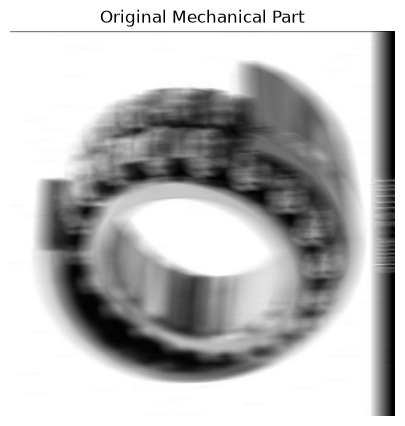

In [3]:
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_PATH = (
    PROJECT_DIR
    / "/home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping/test_images/2atffrt_jpg.rf.643668dbe406ee58688975781ed01484.jpg"
)

if not IMAGE_PATH.exists():
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

original = Image.open(IMAGE_PATH).convert("RGB")

print("Image:", IMAGE_PATH.name)
print("Dimensions:", original.size)

plt.figure(figsize=(7, 5))
plt.imshow(original)
plt.title("Original Mechanical Part")
plt.axis("off")
plt.show()

In [10]:
import os
import json
import base64
import boto3
from pathlib import Path
from dotenv import load_dotenv
from PIL import Image
from IPython.display import display

PROJECT_DIR = Path(
    "/home/abi/vison-model/Vision-Based Product Attribution and BOM Mapping"
)

load_dotenv(PROJECT_DIR / ".env")

os.environ["AWS_BEARER_TOKEN_BEDROCK"] = os.environ["BEDROCK_API_KEY"]

client = boto3.client(
    "bedrock-runtime",
    region_name=os.getenv("AWS_REGION", "us-east-1")
)

MODEL_ID = "global.anthropic.claude-haiku-5-5"

print("Claude Haiku client initialized.")

Claude Haiku client initialized.


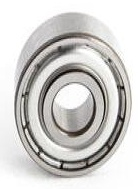

Image dimensions: (138, 189)


In [7]:
IMAGE_PATH = (
    PROJECT_DIR
    / "data/combined/crops/bearing/CROP-000344.jpg"
)

image = Image.open(IMAGE_PATH).convert("RGB")

display(image)
print("Image dimensions:", image.size)

In [16]:
import io

buffer = io.BytesIO()
image.save(buffer, format="JPEG", quality=90)

image_base64 = base64.b64encode(
    buffer.getvalue()
).decode("utf-8")

request_body = {
    "anthropic_version": "bedrock-2023-05-31",
    "max_tokens": 500,
    "messages": [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "source": {
                        "type": "base64",
                        "media_type": "image/jpeg",
                        "data": image_base64,
                    },
                },
                {
                    "type": "text",
                    "text": """
Assess this mechanical-part image for computer vision.

Return:
- Image quality: good, blurry, or uncertain
- Blur severity: low, medium, or high
- Are the part boundaries clearly visible?
- Are important details such as threads, teeth, or holes visible?
- Is the image suitable for YOLO detection and visual similarity retrieval?
- What should be done next?

Do not invent missing details or identify a manufacturer or SKU.
Return a concise assessment.
""",
                },
            ],
        }
    ],
}

response = client.invoke_model(
    modelId=MODEL_ID,
    body=json.dumps(request_body),
    contentType="application/json",
    accept="application/json",
)



In [17]:
content = result.get("content", [])

for item in content:
    if item.get("type") == "text":
        print(item.get("text", ""))
    else:
        print("Non-text content block:")
        print(json.dumps(item, indent=2, default=str))

if not content:
    print("No content blocks returned.")
    print("Response:", json.dumps(result, indent=2, default=str))

Non-text content block:
{
  "type": "thinking",
  "thinking": "",
  "signature": "CAQS1AcKEggSEAEYAjgBQgh0aGlua2luZxIMg3UGydgLldLee+O5GgwfjrOw8FxD7DuXvEUiMAY9wR4N0v+5zyUPbWYdT9tIIAsyQ1GCL4pprVghSusiY1I30ZGs5jyVdWQaMDLZiirvBsCblt1AjblAZhni4iEyp69EAtNH4zR1S0guPyajpqcEbuefKt3fEAPRYYkQQzBCeHg8o9k5bXhAokBwilTPqWL22Q0Fw/l1ua4rFsCXUyCXTkiU4wgXgsuij9vzTHWriZ6jnkC7v0Tqwjh7laR3Sw9j9EtH3+xcA9geip2YakcRbqgXB9UhZXqYXKpXfRzLO9bKRRgTf/nx5Rz02N5wgEyhVxPGTdTsLcRszVzgCGLoOXums0MzL94iqMThRDtbZn80ptwCf5dh+EykzvnTtp/NM1GBEZaaygeHDr73um+8X39MBRIG/gS4veua1oFjrRZM4CVGx064EJ/Kw9WUOMeI587Lv5yNL2oGG9NAJA3Dx1FRJAL+rT9P7czoq4xlPqguaVLAqHM7fAlH2cUpYu4KxfGKgE3hPYxmLQ4PnFpl/cYakGw3un80gHF7on5WmDTttvxa2HbQJEdSR2qAorFXTt7Lw6yPDKe3Am29mbd+uqiWTdtSmSQ+u0j7T1DaO5Gs544k3f/+sLZkKWZMn1r+NJEidcYFYEsQsKcH83dnpJTB9CdzMeHv8meUKBhZ62Mlrsa6Lz+JGuGKfZjc05dnsLmUU3qqrkeb+y256wNGRLkPulQCHOV6aoCX7mtjzUbUxKufdrkm0AbUFluG1yDOnLwgOy24PrazDOr+IGuw2hMN2Hdpow7XoINL0rcOBJhI5tNP+HRbYXrSrEjrMc9e87naQRiLkR+0VLLQBzgjL99wXbZ84G3e9K/9Bt6EXA68nxgiY0